In [1]:
import pandas as pd
import glob

# Path to all CSVs (adjust this to your Kaggle download folder)
path = "./CICIDS2017/"  

# Load all CSV files into a list
all_files = glob.glob(path + "*.csv")

# Combine into one DataFrame
df_list = [pd.read_csv(file) for file in all_files]
df = pd.concat(df_list, ignore_index=True)
df = df.sample(n=20000, random_state=42)

print("Combined shape:", df.shape)
print("Columns:", df.columns[:10], "...")
print("Unique labels:", df[' Label'].unique())


Combined shape: (20000, 79)
Columns: Index([' Destination Port', ' Flow Duration', ' Total Fwd Packets',
       ' Total Backward Packets', 'Total Length of Fwd Packets',
       ' Total Length of Bwd Packets', ' Fwd Packet Length Max',
       ' Fwd Packet Length Min', ' Fwd Packet Length Mean',
       ' Fwd Packet Length Std'],
      dtype='object') ...
Unique labels: ['BENIGN' 'DoS Hulk' 'PortScan' 'DDoS' 'DoS slowloris' 'DoS GoldenEye'
 'FTP-Patator' 'DoS Slowhttptest' 'Bot' 'SSH-Patator' 'Web Attack � XSS'
 'Web Attack � Brute Force' 'Infiltration']


In [2]:
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
from scipy.stats import mode
import time
import os
from joblib import dump, load
import os
from scipy.stats import mode
from tqdm import tqdm
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
import torch.optim as optim
    

In [3]:
SEED = 42
NUM_FEATURES = 10

In [4]:
# df.dtypes

In [5]:
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()

# Strip spaces from column names
df.columns = df.columns.str.strip()

In [6]:
categorical_cols = df.select_dtypes(include='object').columns
label_encoders = {}

le = LabelEncoder()
for col in categorical_cols:
    df[col] = le.fit_transform(df[col].astype(str))
    label_encoders[col] = le
    print(f"\nColumn: {col}")
    print(dict(zip(le.classes_, le.transform(le.classes_))))


Column: Label
{'BENIGN': 0, 'Bot': 1, 'DDoS': 2, 'DoS GoldenEye': 3, 'DoS Hulk': 4, 'DoS Slowhttptest': 5, 'DoS slowloris': 6, 'FTP-Patator': 7, 'Infiltration': 8, 'PortScan': 9, 'SSH-Patator': 10, 'Web Attack � Brute Force': 11, 'Web Attack � XSS': 12}


In [7]:
feature_names = df.columns
X = df.drop('Label', axis=1)   # note: 'Label' (no space after cleaning)
y = df['Label']

# Train/test split
SEED = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Original class distribution (train): {np.bincount(y_train)}")

Original class distribution (train): [12867    15   676    57  1272    33    34    51     1   940    28     2
     6]


In [8]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [9]:
pca = PCA(n_components=NUM_FEATURES, random_state=SEED)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test_scaled)

print("Features Selected: ")
for i, component in enumerate(pca.components_):
    important_idx = np.argmax(np.abs(component))
    print(f"Principal Component {i+1}: most important feature is '{feature_names[important_idx]}'")

Features Selected: 
Principal Component 1: most important feature is 'Flow IAT Max'
Principal Component 2: most important feature is 'Total Backward Packets'
Principal Component 3: most important feature is 'Fwd IAT Min'
Principal Component 4: most important feature is 'Avg Fwd Segment Size'
Principal Component 5: most important feature is 'min_seg_size_forward'
Principal Component 6: most important feature is 'ACK Flag Count'
Principal Component 7: most important feature is 'Active Max'
Principal Component 8: most important feature is 'Fwd IAT Min'
Principal Component 9: most important feature is 'Active Mean'
Principal Component 10: most important feature is 'URG Flag Count'


In [10]:
X_train = X_train_pca
X_test = X_test_pca

print(X_train.shape, X_test.shape)

(15982, 10) (3996, 10)


In [11]:
# from qiskit_ibm_runtime import QiskitRuntimeService
# QiskitRuntimeService.save_account(
#     channel="ibm_quantum",  
#     token="v-uYI15U6wsQ0TyrumMduQcg6Jm99UMi09CSA05q9AFk",
#     overwrite=True
# )

# service = QiskitRuntimeService(channel="ibm_quantum")


# # v-uYI15U6wsQ0TyrumMduQcg6Jm99UMi09CSA05q9AFk

In [12]:
n_layers = 5
n_classes = len(y.unique())

dev = qml.device("default.qubit", wires=NUM_FEATURES)
# dev = qml.device("qiskit.ibmq", wires=NUM_FEATURES, backend="ibmq_qasm_simulator")

@qml.qnode(dev)
def qnn_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(NUM_FEATURES))
    qml.StronglyEntanglingLayers(weights, wires=range(NUM_FEATURES))
    return [qml.expval(qml.PauliZ(i)) for i in range(NUM_FEATURES)]

qnode = qml.QNode(qnn_circuit, dev, interface="torch")

class QNNClassifierMulti(nn.Module):
    def __init__(self, n_layers, n_qubits, n_classes):
        super().__init__()
        weight_shapes = {"weights": (n_layers, n_qubits, 3)}
        self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
        self.fc = nn.Linear(n_qubits, n_classes)  # output = n_classes
    
    def forward(self, x):
        x = self.qlayer(x)
        x = self.fc(x)
        return x  # logits for each class

# class QNNClassifier(nn.Module):
#     def __init__(self, n_layers, n_qubits):
#         super().__init__()
#         weight_shapes = {"weights": (n_layers, n_qubits, 3)}
#         self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
#         self.fc = nn.Linear(n_qubits, 1)
    
#     def forward(self, x):
#         x = self.qlayer(x)
#         x = self.fc(x)
#         return x  # No sigmoid here




In [13]:
# Prepare data (example subset)
X_train_tensor = torch.tensor(X_train[:3000], dtype=torch.float32)
y_train_tensor = torch.tensor(y_train[:3000].values, dtype=torch.long)  # long for CE loss
X_test_tensor = torch.tensor(X_test[:1000], dtype=torch.float32)
y_test_tensor = torch.tensor(y_test[:1000].values, dtype=torch.long)

# Dataloader
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# Model, loss, optimizer
model_multi = QNNClassifierMulti(n_layers=n_layers, n_qubits=NUM_FEATURES, n_classes=n_classes)
criterion = nn.CrossEntropyLoss() # removed BCEWithLogitsLoss because it is used for binary calssification
optimizer = optim.Adam(model_multi.parameters(), lr=0.01)

# Training loop
epochs = 100
for epoch in range(epochs):
    model_multi.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model_multi(X_batch)              # shape: (batch, n_classes)
        loss = criterion(outputs, y_batch)          # CE loss expects logits + class indices
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    # if (epoch+1) % 10 == 0:
    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")


model_multi.eval()
with torch.no_grad():
    logits = model_multi(X_test_tensor)       # (N, n_classes)
    probs = torch.softmax(logits, dim=1)      # class probabilities
    preds = torch.argmax(probs, dim=1).numpy()

acc = accuracy_score(y_test_tensor, preds)
print(f"Multiclass QNN Accuracy: {acc:.4f}")


Epoch 1/100, Loss: 1.6539
Epoch 2/100, Loss: 0.7268
Epoch 3/100, Loss: 0.5566
Epoch 4/100, Loss: 0.4680
Epoch 5/100, Loss: 0.4176
Epoch 6/100, Loss: 0.3785
Epoch 7/100, Loss: 0.3553
Epoch 8/100, Loss: 0.3370
Epoch 9/100, Loss: 0.3260
Epoch 10/100, Loss: 0.3135
Epoch 11/100, Loss: 0.3052
Epoch 12/100, Loss: 0.2952
Epoch 13/100, Loss: 0.2878
Epoch 14/100, Loss: 0.2865
Epoch 15/100, Loss: 0.2787
Epoch 16/100, Loss: 0.2686
Epoch 17/100, Loss: 0.2627
Epoch 18/100, Loss: 0.2595
Epoch 19/100, Loss: 0.2558
Epoch 20/100, Loss: 0.2513
Epoch 21/100, Loss: 0.2475
Epoch 22/100, Loss: 0.2438
Epoch 23/100, Loss: 0.2405
Epoch 24/100, Loss: 0.2358
Epoch 25/100, Loss: 0.2326
Epoch 26/100, Loss: 0.2370
Epoch 27/100, Loss: 0.2241
Epoch 28/100, Loss: 0.2274
Epoch 29/100, Loss: 0.2234
Epoch 30/100, Loss: 0.2209
Epoch 31/100, Loss: 0.2164
Epoch 32/100, Loss: 0.2190
Epoch 33/100, Loss: 0.2146
Epoch 34/100, Loss: 0.2125
Epoch 35/100, Loss: 0.2094
Epoch 36/100, Loss: 0.2081
Epoch 37/100, Loss: 0.2058
Epoch 38/1

In [14]:
print("Classification Report:\n", 
      classification_report(
          y_test_tensor, 
          preds, 
          target_names=[str(c) for c in np.unique(y_test_tensor)]
      ))

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.96      0.96       805
           2       0.92      0.84      0.88        43
           3       0.00      0.00      0.00         3
           4       0.94      0.84      0.88        87
           5       0.00      0.00      0.00         2
           6       0.50      0.33      0.40         3
           7       0.00      0.00      0.00         1
           9       0.70      0.96      0.81        55
          10       0.00      0.00      0.00         1

    accuracy                           0.94      1000
   macro avg       0.45      0.44      0.44      1000
weighted avg       0.94      0.94      0.93      1000



/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


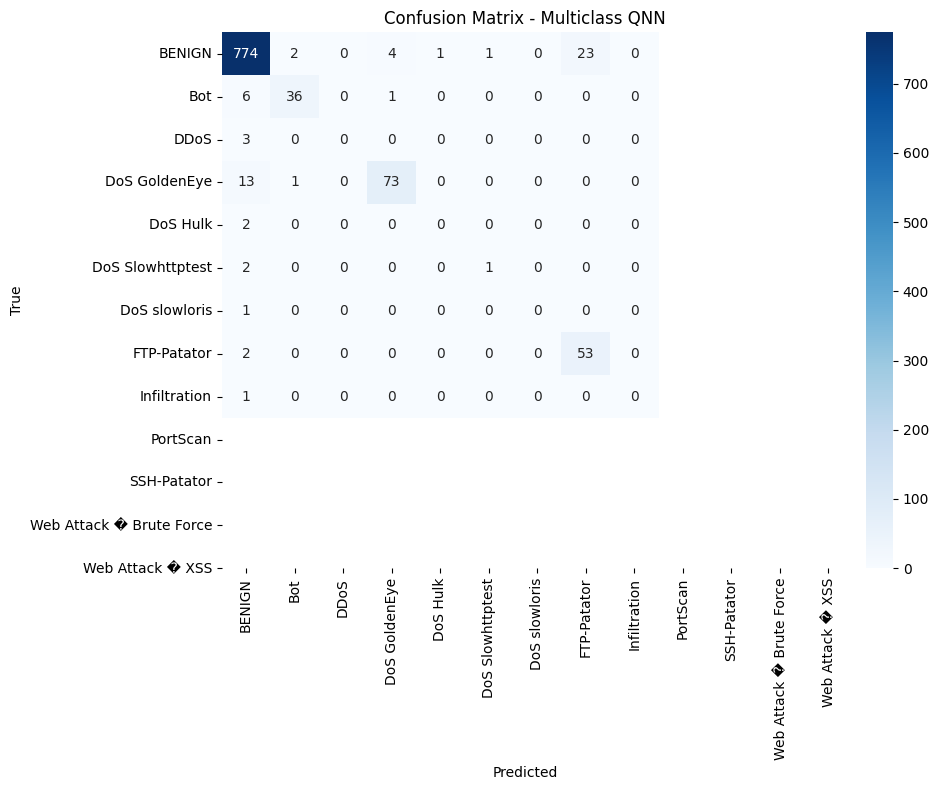

: 

In [ ]:
cm = confusion_matrix(y_test_tensor, preds)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Confusion Matrix - Multiclass QNN")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.tight_layout()
plt.show()